●Write a program to implement the local binary pattern on gray scale
image.
● Write a program to denoise the input image corrupted by Gaussian and
Speckle noise by using following filters (3x3 or 5x5 window).
(a) Weiner filter
(b) Median filtering
(c) Gaussian filter
(d) Bilateral filter

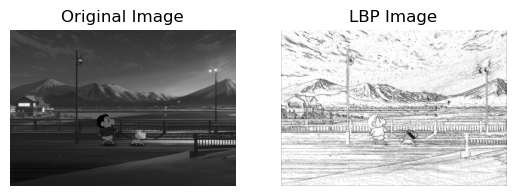

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread('wallpaper.jpg', 0)

# Create output image
lbp = np.zeros_like(img)

# Apply LBP
for i in range(1, img.shape[0]-1):
    for j in range(1, img.shape[1]-1):

        center = img[i, j]
        pixels = [
            img[i-1, j-1], img[i-1, j],
            img[i-1, j+1], img[i, j+1],
            img[i+1, j+1], img[i+1, j],
            img[i+1, j-1], img[i, j-1]
        ]

        value = 0
        for k in range(8):
            if pixels[k] >= center:
                value += 2**k

        lbp[i, j] = value

# Display images
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title('LBP Image')
plt.axis('off')

plt.show()

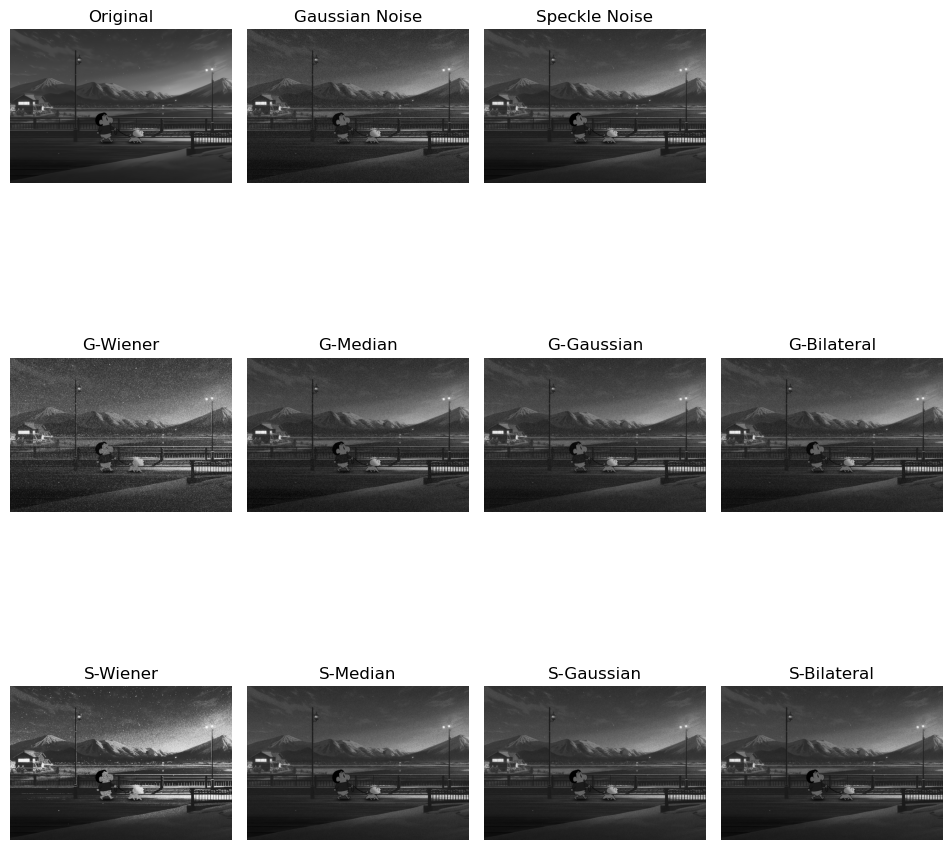

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('wallpaper.jpg', 0)

# Convert image to float
img = img.astype(np.float32) / 255.0

# Add Gaussian noise
gaussian_noise = img + np.random.normal(0, 0.1, img.shape)
gaussian_noise = np.clip(gaussian_noise, 0, 1)

# Add Speckle noise
speckle_noise = img + img * np.random.normal(0, 0.2, img.shape)
speckle_noise = np.clip(speckle_noise, 0, 1)

# Convert to 8-bit image
gaussian_noise = np.uint8(gaussian_noise * 255)
speckle_noise = np.uint8(speckle_noise * 255)

# Function to apply filters
def apply_filters(noisy):

    # Wiener filter
    mean = cv2.blur(noisy, (3, 3))
    mean_sq = cv2.blur(noisy.astype(np.float32)**2, (3, 3))
    variance = mean_sq - mean.astype(np.float32)**2
    noise_var = np.mean(variance)

    wiener = mean + (np.maximum(variance - noise_var, 0) /
                     (variance + 1e-8)) * (noisy - mean)

    wiener = np.uint8(np.clip(wiener, 0, 255))

    # Median filter
    median = cv2.medianBlur(noisy, 3)

    # Gaussian filter
    gaussian = cv2.GaussianBlur(noisy, (3, 3), 0)

    # Bilateral filter
    bilateral = cv2.bilateralFilter(noisy, 5, 50, 50)

    return wiener, median, gaussian, bilateral

# Apply filters
g_filters = apply_filters(gaussian_noise)
s_filters = apply_filters(speckle_noise)

# Display results
titles = ['Wiener', 'Median', 'Gaussian', 'Bilateral']

plt.figure(figsize=(12, 10))

plt.subplot(3, 5, 1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(3, 5, 2)
plt.imshow(gaussian_noise, cmap='gray')
plt.title('Gaussian Noise')
plt.axis('off')

plt.subplot(3, 5, 3)
plt.imshow(speckle_noise, cmap='gray')
plt.title('Speckle Noise')
plt.axis('off')

for i in range(4):
    plt.subplot(3, 5, 6+i)
    plt.imshow(g_filters[i], cmap='gray')
    plt.title('G-' + titles[i])
    plt.axis('off')

    plt.subplot(3, 5, 11+i)
    plt.imshow(s_filters[i], cmap='gray')
    plt.title('S-' + titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()